## Stock Price Predictor

In [1]:
import numpy as np
import pandas as pd

import yfinance as yf

import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
stock = input('Enter the code of the Stock: ')
data = yf.download(stock, "2008-01-01", "2021-11-27", auto_adjust=True)
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2008-01-02,5.827592,5.989703,5.759100,5.960093,1079178800
2008-01-03,5.830284,5.903862,5.763287,5.844641,842066400
2008-01-04,5.385229,5.772558,5.350534,5.726199,1455832000
2008-01-07,5.313146,5.491407,5.091515,5.421119,2072193200
2008-01-08,5.122026,5.457314,5.108567,5.387922,1523816000


In [3]:
data.shape

(3502, 5)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3502 entries, 2008-01-02 to 2021-11-26
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   3502 non-null   float64
 1   (High, AAPL)    3502 non-null   float64
 2   (Low, AAPL)     3502 non-null   float64
 3   (Open, AAPL)    3502 non-null   float64
 4   (Volume, AAPL)  3502 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 164.2 KB


In [5]:
data.describe()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,3502.000000,3502.000000,3502.000000,3502.000000,3.502000e+03
mean,34.006137,34.345437,33.638065,33.991330,3.549342e+08
std,35.502923,35.876891,35.090480,35.481705,3.386953e+08
min,2.338933,2.452589,2.338933,2.374525,4.100000e+07
25%,10.592046,10.703163,10.513836,10.615900,1.189352e+08
50%,22.048097,22.253759,21.818362,22.071900,2.307598e+08
75%,41.105791,41.380870,40.746091,41.015512,4.658745e+08
max,158.182129,161.854901,157.263968,157.928182,3.372970e+09


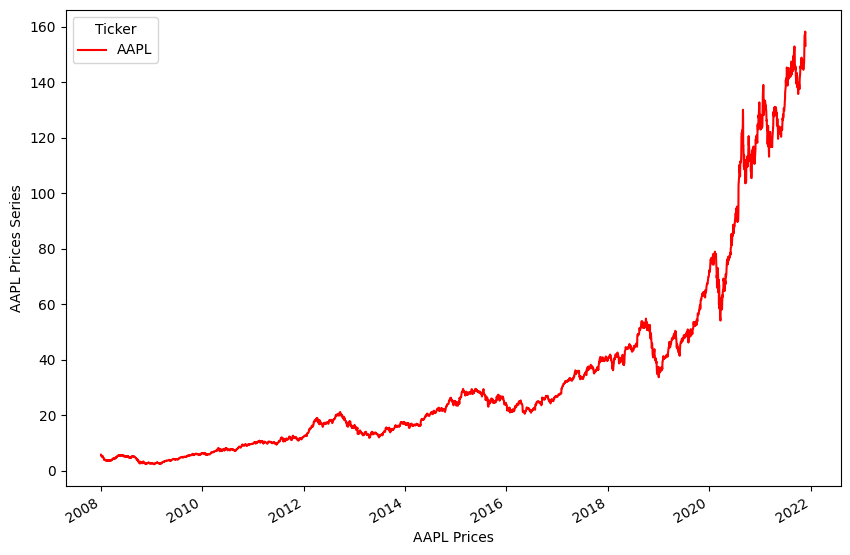

In [6]:
data.Close.plot(figsize=(10,7), color='r')
plt.xlabel(f"{stock} Prices")
plt.ylabel(f"{stock} Prices Series")
plt.show()

<Axes: ylabel='Density'>

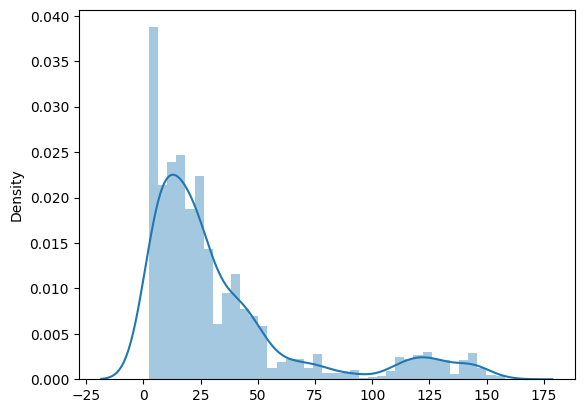

In [7]:
sns.distplot(data.Open)

<Axes: ylabel='Density'>

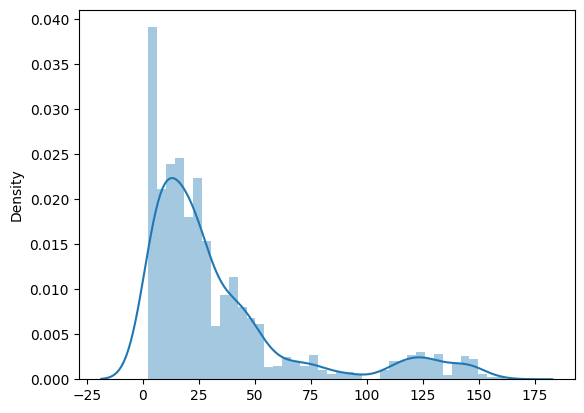

In [8]:
sns.distplot(data.High)

<Axes: ylabel='Density'>

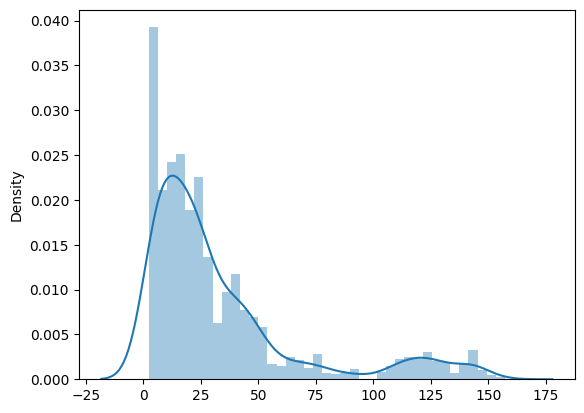

In [9]:
sns.distplot(data.Low)

<Axes: ylabel='Density'>

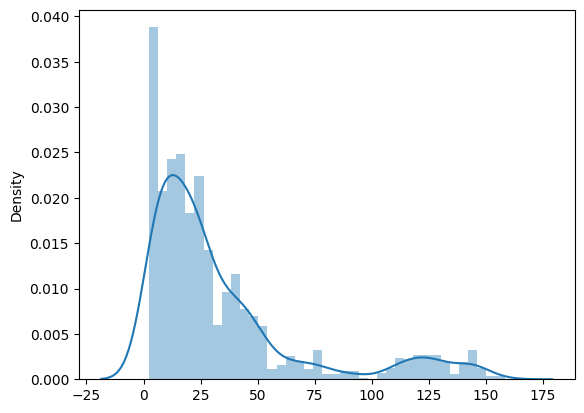

In [10]:
sns.distplot(data.Close)

### Conlusions
- Shape the of the data
- How our data is distributed
- It's is very very non-linear 

In [11]:
X = data.drop('Close', axis = 1)
y = data['Close']

## Training and Testing Dataset

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=0)

In [13]:
print(X_train.shape, X_test.shape,y_train.shape,y_test.shape)

(2801, 4) (701, 4) (2801, 1) (701, 1)


## Modeling Part

In [14]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
pred = model_lr.predict(X_test)

In [15]:
# Predict value print
pred

array([[ 15.23511248],
       [  5.30929373],
       [125.64346723],
       [ 44.62082877],
       [ 15.90142105],
       [ 26.149733  ],
       [ 36.59846274],
       [ 28.13974861],
       [  7.71745575],
       [ 11.56771251],
       [ 17.79175421],
       [  2.65651887],
       [ 75.76998296],
       [  3.63174732],
       [ 27.55730425],
       [  2.51491003],
       [123.75028317],
       [ 14.95699509],
       [ 17.05343752],
       [ 26.15710284],
       [  3.23556552],
       [ 42.53357251],
       [147.23442671],
       [ 24.58478342],
       [ 46.34897286],
       [  2.54743897],
       [  7.6136957 ],
       [ 10.16322212],
       [ 15.36358084],
       [ 11.8777497 ],
       [  7.70960367],
       [ 10.26435963],
       [ 43.8986301 ],
       [ 40.42090425],
       [120.28378577],
       [  2.85596282],
       [  7.04647874],
       [  7.56281561],
       [ 34.6063982 ],
       [ 40.88072965],
       [  8.49961283],
       [ 16.10344199],
       [  3.76159523],
       [130

In [16]:
# MSE (Mean Square Error)
# RMSE (Root Mean Square Error)
# r2_square --> 1.0 -> Very Good Model

from sklearn.metrics import mean_squared_error, r2_score

def calculate_metrics(y_test, y_pred):
    '''
        y_test: ground truth
        y_pred: model predict value
    '''
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2_scores = r2_score(y_test, y_pred)
    print('*'*50)
    print(f"*  Mean Square Error: {mse}")
    print(f"*  Root Mean Square Error: {rmse}")
    print(f"*  r2_score: {r2_scores}")
    print('*'*50)

calculate_metrics(y_test, pred)

**************************************************
*  Mean Square Error: 0.11251561007640892
*  Root Mean Square Error: 0.33543346594579515
*  r2_score: 0.9999138496106379
**************************************************


### Lasso and Ridge Model

In [17]:
from sklearn.linear_model import Lasso, Ridge

model_lasso = Lasso().fit(X_train, y_train)
model_ridge = Ridge().fit(X_train, y_train)

model_lasso_pred = model_lasso.predict(X_test)
model_ridge_pred = model_ridge.predict(X_test)

In [18]:
calculate_metrics(y_test, model_lasso_pred)

calculate_metrics(y_test, model_ridge_pred)

**************************************************
*  Mean Square Error: 0.2358301002248437
*  Root Mean Square Error: 0.48562341399982323
*  r2_score: 0.9998194307888134
**************************************************
**************************************************
*  Mean Square Error: 0.11263177439783753
*  Root Mean Square Error: 0.33560657680956957
*  r2_score: 0.9999137606665215
**************************************************


## Support Vector Machine Regression

In [19]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

params = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
    'kernel': ['rbf']
}

params_grid = GridSearchCV(SVR(), params, refit=True, verbose=3)
params_grid.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.131 total time=   0.1s
[CV 2/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.076 total time=   0.1s
[CV 3/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.128 total time=   0.1s
[CV 4/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.126 total time=   0.1s
[CV 5/5] END .......C=0.1, gamma=1, kernel=rbf;, score=-0.124 total time=   0.1s
[CV 1/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.131 total time=   0.1s
[CV 2/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.076 total time=   0.2s
[CV 3/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.128 total time=   0.1s
[CV 4/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.126 total time=   0.2s
[CV 5/5] END .....C=0.1, gamma=0.1, kernel=rbf;, score=-0.124 total time=   0.2s
[CV 1/5] END ....C=0.1, gamma=0.01, kernel=rbf;, score=-0.131 total time=   0.1s
[CV 2/5] END ....C=0.1, gamma=0.01, kernel=rbf;

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVR()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and c

In [20]:
model_svr = SVR(C=10, gamma=0.1, kernel='rbf')
model_svr.fit(X_train, y_train)
svr_pred = model_svr.predict(X_test)

## Model Save

In [21]:
import joblib  

joblib.dump(model_ridge, 'model.pkl') 

ridge_from_joblib = model = joblib.load("model.pkl")